# Introduction

## Data Visualization and Feature Analysis
This notebook performs data visualization and feature analysis on the **Wisconsin Breast Cancer Dataset**. The key objectives include:

- Understanding the dataset and its attributes.
- Visualizing feature distributions and correlations.

## About the Dataset

The **Wisconsin Breast Cancer Dataset** is sourced from the UCI Machine Learning Repository. It is a well-known dataset for binary classification tasks, specifically aimed at predicting whether a tumor is **benign** or **malignant** based on features computed from cell nuclei images.

## Key Details:
- **Number of Instances**: 569
- **Number of Features**: 30 numeric features (mean, standard error, and worst-case values for 10 cell features).
- **Target Variable**:
  - `0`: Benign (non-cancerous)
  - `1`: Malignant (cancerous)

## Features:
The features are categorized into three groups:
1. **Mean Values**: Average measurements of cell features (e.g., `Radius_mean`, `Texture_mean`).
2. **Standard Error (SE) Values**: Variability of cell features (e.g., `Radius_se`, `Texture_se`).
3. **Worst Values**: Maximum or worst-case measurements of cell features (e.g., `Radius_worst`, `Texture_worst`).

## Features Description:
- **Radius**: Mean distance from the center to points on the perimeter.
- **Texture**: Standard deviation of gray-scale values.
- **Perimeter**: Length of the boundary of the cell nuclei.
- **Area**: Size of the cell nuclei.
- **Smoothness**: Variation in smoothness of the cell nuclei boundary.
- **Compactness**: Ratio of perimeter² to area minus 1.0.
- **Concavity**: Severity of concave portions of the boundary.
- **Concave Points**: Number of concave portions of the boundary.
- **Symmetry**: Symmetry of the cell nuclei.
- **Fractal Dimension**: “Coastline approximation” — quantifies shape complexity.

# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Loading Data

In [2]:
columns = [
    "ID", "Diagnosis", "Radius_mean", "Texture_mean", "Perimeter_mean", "Area_mean", "Smoothness_mean", 
    "Compactness_mean", "Concavity_mean", "Concave_points_mean", "Symmetry_mean", "Fractal_dimension_mean",
    "Radius_se", "Texture_se", "Perimeter_se", "Area_se", "Smoothness_se", "Compactness_se", "Concavity_se",
    "Concave_points_se", "Symmetry_se", "Fractal_dimension_se", "Radius_worst", "Texture_worst", "Perimeter_worst",
    "Area_worst", "Smoothness_worst", "Compactness_worst", "Concavity_worst", "Concave_points_worst",
    "Symmetry_worst", "Fractal_dimension_worst"
]
data = pd.read_csv("wdbc.data",header=None, names=columns)
data = data.drop("ID", axis=1) #ID coloumn is not useful

In [3]:
data.head(10)

,Diagnosis,Radius_mean,Texture_mean,Perimeter_mean,Area_mean,Smoothness_mean,Compactness_mean,Concavity_mean,Concave_points_mean,Symmetry_mean,...,Radius_worst,Texture_worst,Perimeter_worst,Area_worst,Smoothness_worst,Compactness_worst,Concavity_worst,Concave_points_worst,Symmetry_worst,Fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


# Inspecting and Analysing the Data

## Exploratory Data Analysis
EDA is performed to understand the dataset's statistical properties and feature distributions. Key visualizations include:

1. **Histograms**: To visualize the distribution of individual features.
2. **Box Plots**: To identify outliers.
3. **Correlation Heatmap**: To explore relationships between features.

In [4]:
data.shape

(569, 31)

In [5]:
data.describe()

,Radius_mean,Texture_mean,Perimeter_mean,Area_mean,Smoothness_mean,Compactness_mean,Concavity_mean,Concave_points_mean,Symmetry_mean,Fractal_dimension_mean,...,Radius_worst,Texture_worst,Perimeter_worst,Area_worst,Smoothness_worst,Compactness_worst,Concavity_worst,Concave_points_worst,Symmetry_worst,Fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [6]:
data.groupby("Diagnosis").mean()

,Radius_mean,Texture_mean,Perimeter_mean,Area_mean,Smoothness_mean,Compactness_mean,Concavity_mean,Concave_points_mean,Symmetry_mean,Fractal_dimension_mean,...,Radius_worst,Texture_worst,Perimeter_worst,Area_worst,Smoothness_worst,Compactness_worst,Concavity_worst,Concave_points_worst,Symmetry_worst,Fractal_dimension_worst
Diagnosis,,,,,,,,,,,,,,,,,,,,,
B,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442
M,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,...,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530


- Helps understand how the mean values of features differ between the two classes (Benign and Malignant). 
- Features like `Radius_mean`, `Area_mean`, and `Perimeter_mean` tend to have higher mean values for Malignant cases compared to Benign cases.
- If the mean values for certain features are significantly different between the two groups, those features are likely important for classification.

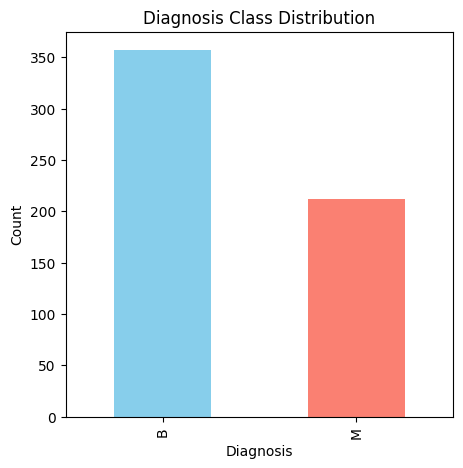

In [7]:
#Plotting the frequency of diagnosis
plt.figure(figsize=(5, 5))
data['Diagnosis'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Diagnosis Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

In [8]:
#Extracting only the mean values for data visualisation
mean_columns = [col for col in data.columns if '_mean' in col]
mean_df = data[mean_columns]
mean_df

,Radius_mean,Texture_mean,Perimeter_mean,Area_mean,Smoothness_mean,Compactness_mean,Concavity_mean,Concave_points_mean,Symmetry_mean,Fractal_dimension_mean
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883
...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016


<Figure size 2000x1500 with 0 Axes>

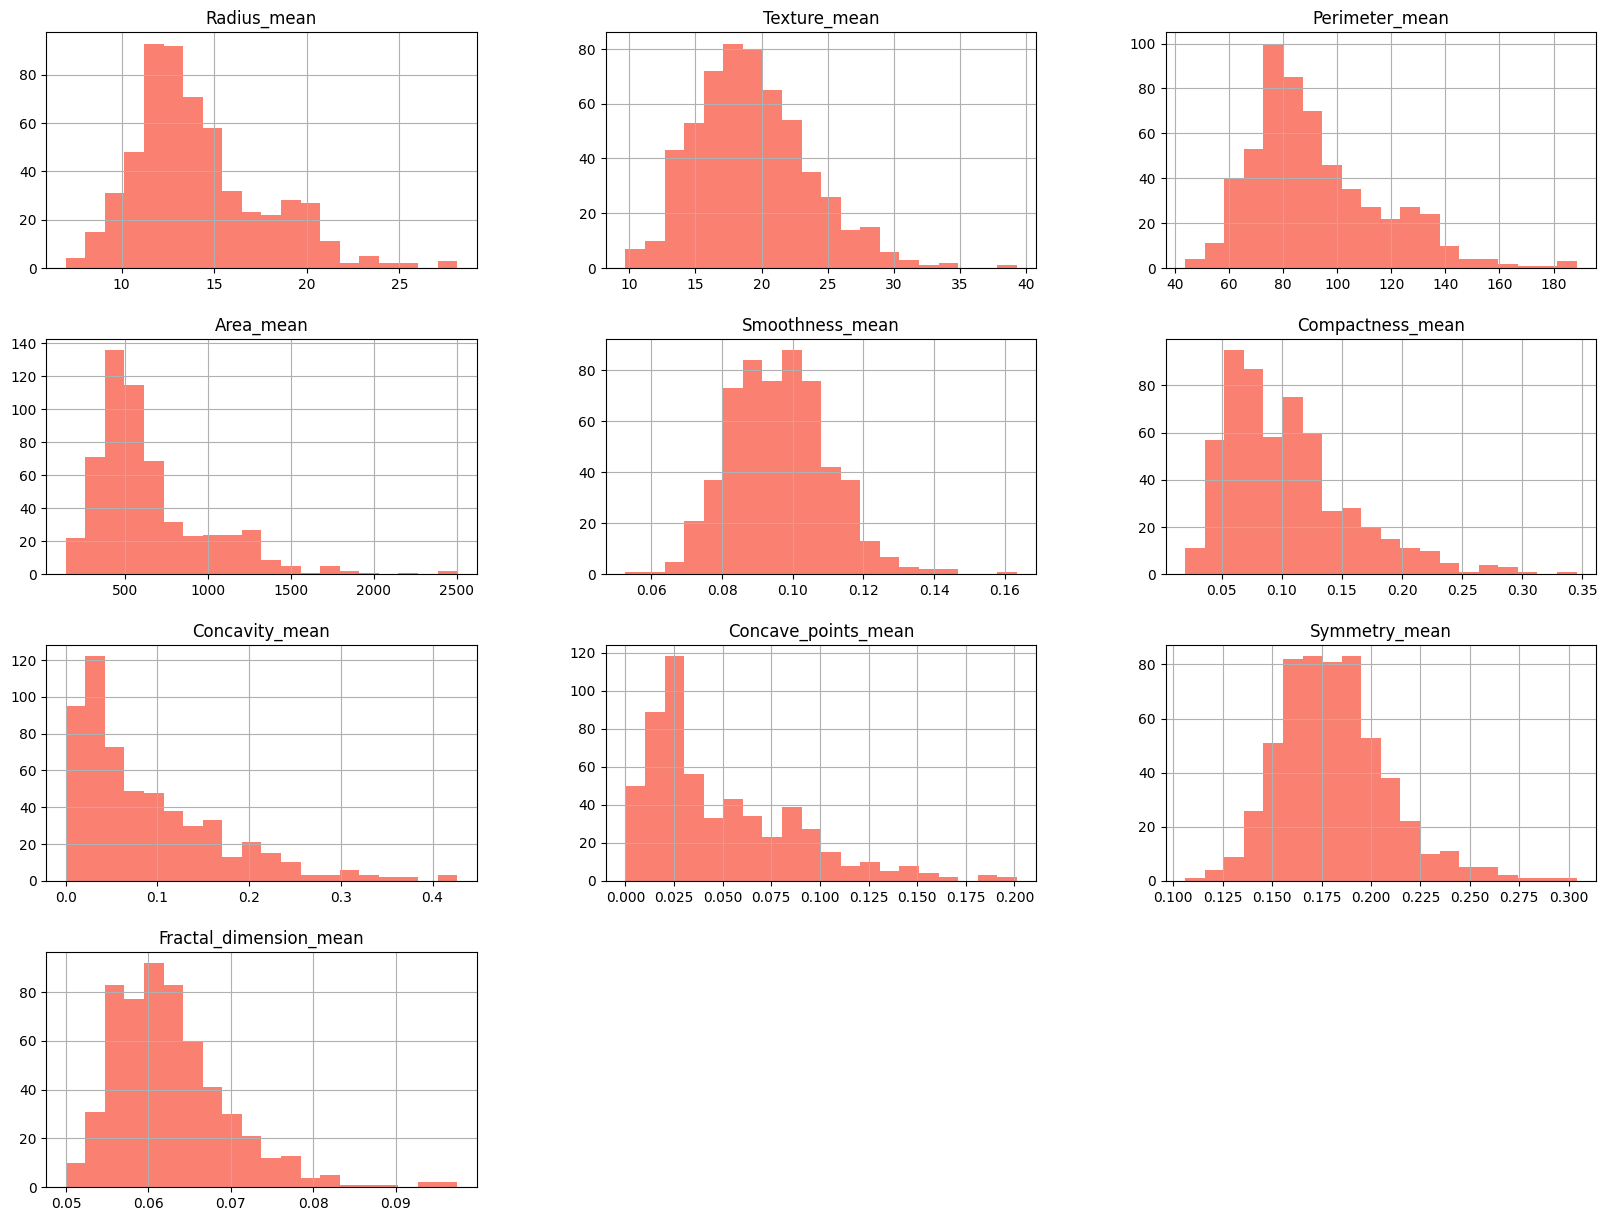

In [9]:
#Histogram of each coloumn
plt.figure(figsize=(20, 15))
mean_df.hist(bins=20, figsize=(20, 15), color='salmon')
plt.show()

- The histograms display the frequency distributions of all numeric features in the dataset.
- Many feaures, such as `Concave_points_mean` and `Perimeter_mean`, are positively skewed, with most values concentrated in lower ranges
- Features like `Smoothness_mean` and `Symmetry_mean` are more uniformly distributed.

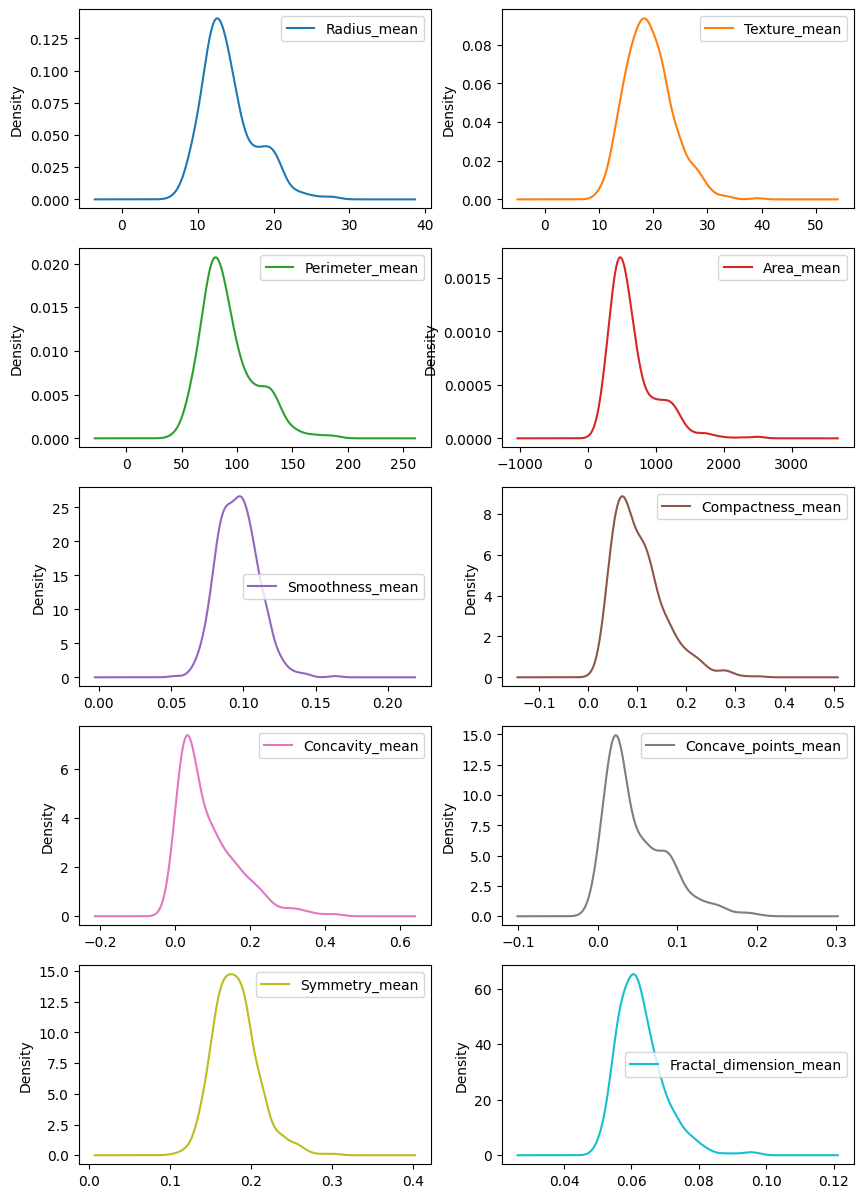

In [10]:
#Density of each coloumn
mean_df.plot(kind='density', subplots=True, layout=(5, 2), figsize=(10, 15), sharex=False, sharey=False)
plt.show()

- Density plots provide a smoother view of the feature distributions, showing how values are concentrated across the range for both benign and malignant cases.
- Features like `Radius_mean`, `Perimeter_mean`, and `Area_mean` show two peaks which is a clear separation between benign and malignant cases, with malignant cases exhibiting peaks at higher values.

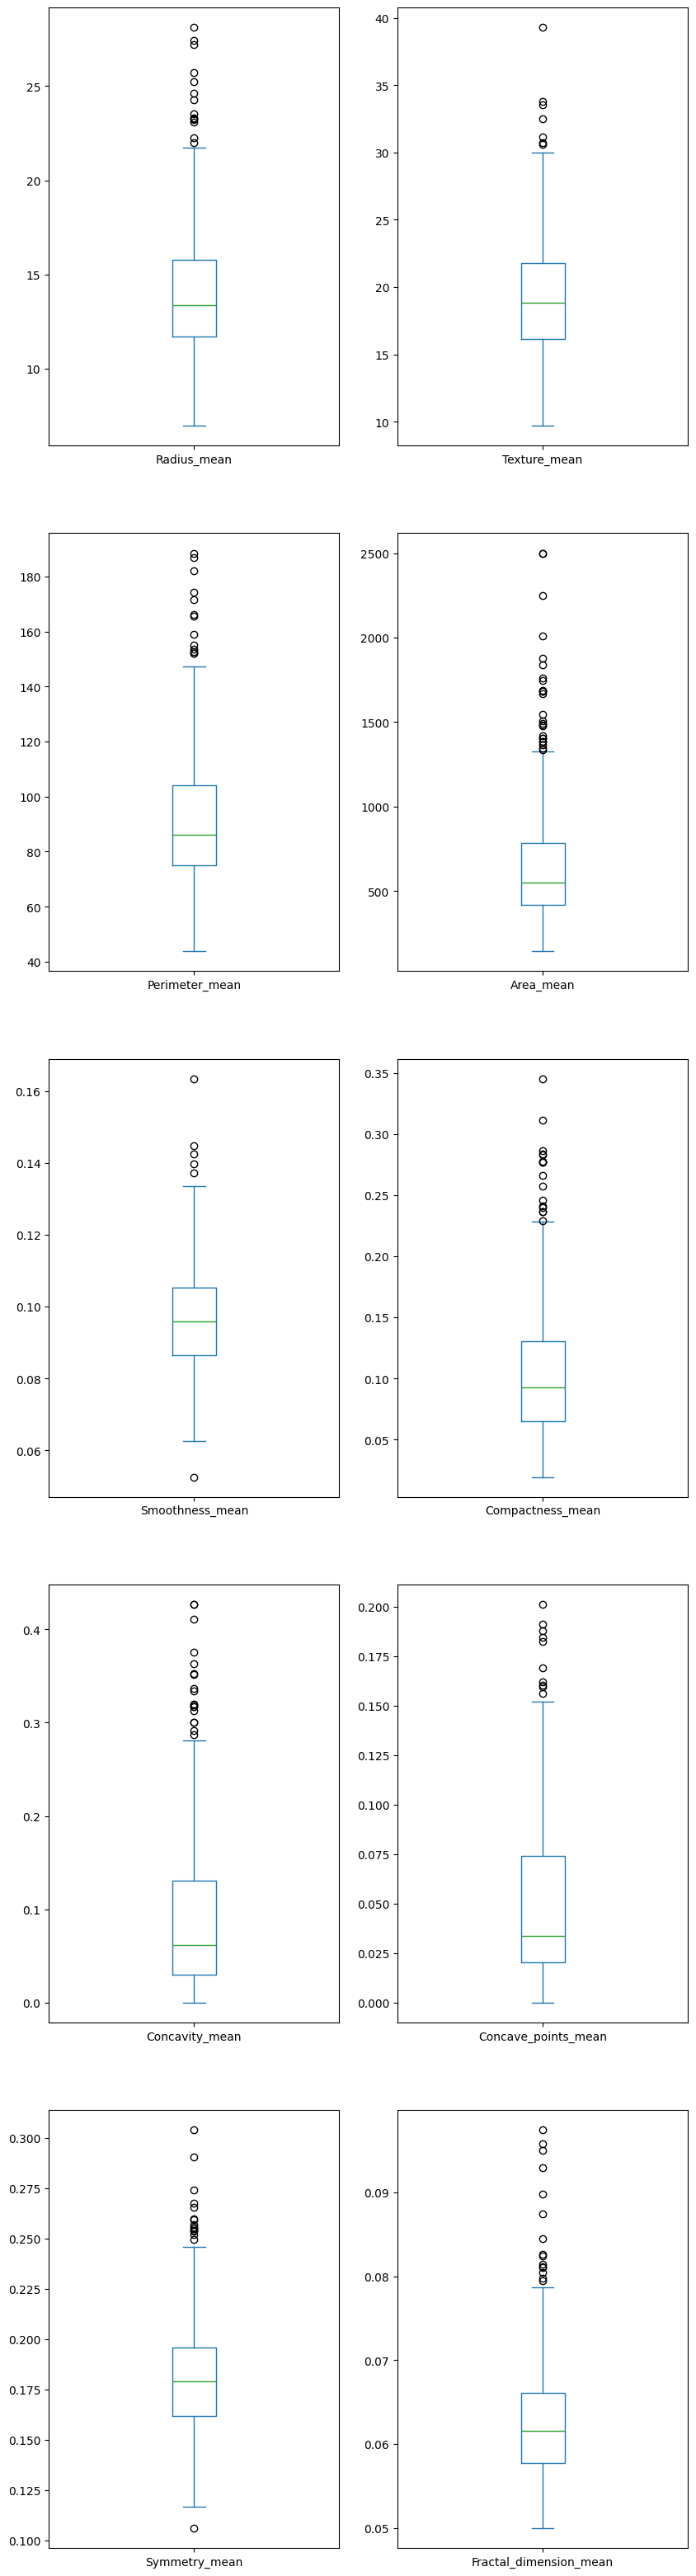

In [11]:
# Box Plot for All Features with Column Name
mean_df.plot(kind='box', subplots=True, layout=(5, 2), figsize=(10, 40), sharex=False, sharey=False)
plt.show()

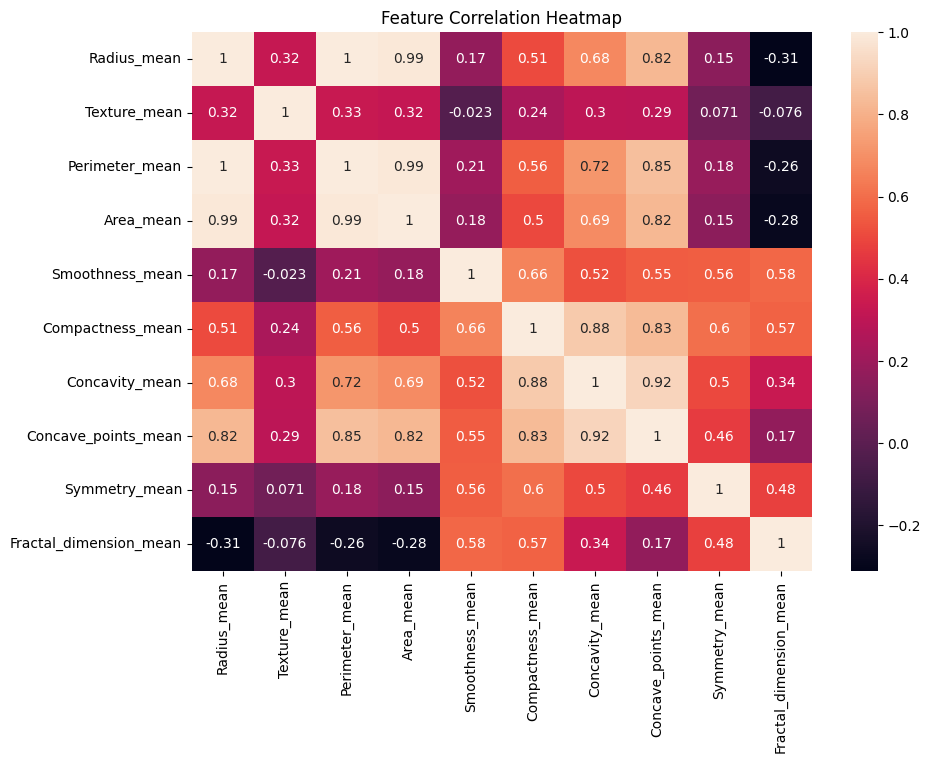

In [12]:
#Correlation between features
plt.figure(figsize=(10, 7))
sns.heatmap(mean_df.corr(),annot=True)
plt.title('Feature Correlation Heatmap')
plt.show()

- Features such as `Radius_mean`, `Perimeter_mean`, and `Area_mean` are highly correlated, indicating they may capture similar information about tumor size.
- Strong correlations among features suggest possible redundancy, which can be addressed by dimensionality reduction techniques like PCA.